# 🔥 guato_ba — Datasets A e B (Zenodo)
### Patches bitemporais Sentinel-2 para detecção de área queimada no Pantanal
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

Este estudo publica **dois datasets** no Zenodo. Ambos são conjuntos de **patches 256×256** recortados do Pantanal, cada patch sendo um **par bitemporal** (duas datas, T1 e T2) de Sentinel-2.

| | Dataset | Arquivos | Patches | Papel |
|---|---|---|---|---|
| **A** | **Treino** (`train_v123_256`) | `T1, T2, Y, G, POS, SPLIT` | **13.004** | treinar/validar (ano 2024) |
| **B** | **Teste OOT** (`test2025`) | `T1, T2, Y, G` | **710** | testar fora da amostra (ano 2025) |

Este notebook é **autossuficiente**: para rodá-lo você só precisa de `numpy` e `matplotlib` e dos arquivos `.npy`. Não precisa do restante do código do repositório.

</div>

# <span style="color:#cf4c39">📂 1. Onde estão os arquivos</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

Rodando a partir do repositório, os `.npy` ficam em `guato_ba/data/`. Se você baixou os zips do **Zenodo**, extraia-os e **aponte a variável `DATA`** para a pasta com os `.npy`.

</div>

In [1]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT/"data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT/"data"          # <- se baixou do Zenodo, troque por Path("/caminho/para/os/npy")
print("Pasta de dados:", DATA)
assert DATA.exists(), "Ajuste DATA para a pasta que contém os arquivos .npy"
sorted(p.name for p in DATA.glob("*.npy"))

Pasta de dados: /home/jovyan/ID-QUEIMADAS/jupyter/guato_ba/data


['test2025_G.npy',
 'test2025_T1.npy',
 'test2025_T2.npy',
 'test2025_Y.npy',
 'train_v123_256_G.npy',
 'train_v123_256_POS.npy',
 'train_v123_256_SPLIT.npy',
 'train_v123_256_T1.npy',
 'train_v123_256_T2.npy',
 'train_v123_256_Y.npy']

# <span style="color:#cf4c39">📐 2. Formato: shapes e dtypes</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

Carregamos em modo **memória-mapeada** (`mmap_mode="r"`) — assim inspecionamos arquivos de vários GB sem carregá-los inteiros na RAM. As matrizes `G`, `POS` e `SPLIT` são pequenas e guardam **metadados** (texto/objetos), então usam `allow_pickle=True`.

</div>

In [2]:
def carregar(nome, mmap=True):
    """Carrega um .npy do dataset. Usa allow_pickle p/ as matrizes de metadados (G/POS/SPLIT)."""
    try:
        return np.load(DATA/f"{nome}.npy", mmap_mode="r" if mmap else None)
    except ValueError:
        return np.load(DATA/f"{nome}.npy", allow_pickle=True)

print("=== Dataset A — treino (train_v123_256) ===")
for nm in ["train_v123_256_T1","train_v123_256_T2","train_v123_256_Y",
           "train_v123_256_G","train_v123_256_POS","train_v123_256_SPLIT"]:
    a = carregar(nm); print(f"  {nm:26s} shape={str(a.shape):22s} dtype={a.dtype}")

print("\n=== Dataset B — teste OOT 2025 (test2025) ===")
for nm in ["test2025_T1","test2025_T2","test2025_Y","test2025_G"]:
    a = carregar(nm); print(f"  {nm:26s} shape={str(a.shape):22s} dtype={a.dtype}")

=== Dataset A — treino (train_v123_256) ===
  train_v123_256_T1          shape=(13004, 4, 256, 256)   dtype=uint16
  train_v123_256_T2          shape=(13004, 4, 256, 256)   dtype=uint16
  train_v123_256_Y           shape=(13004, 256, 256)      dtype=uint8
  train_v123_256_G           shape=(13004,)               dtype=<U4
  train_v123_256_POS         shape=(13004, 3)             dtype=object
  train_v123_256_SPLIT       shape=(13004,)               dtype=uint8

=== Dataset B — teste OOT 2025 (test2025) ===
  test2025_T1                shape=(710, 4, 256, 256)     dtype=uint16
  test2025_T2                shape=(710, 4, 256, 256)     dtype=uint16
  test2025_Y                 shape=(710, 256, 256)        dtype=uint8
  test2025_G                 shape=(710,)                 dtype=<U3


# <span style="color:#cf4c39">🌈 3. As bandas e a reflectância</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

`T1` e `T2` têm forma `(N, 4, 256, 256)`: para cada patch, **4 bandas** Sentinel-2 L2A, **nesta ordem**:

| índice | banda | nome | ~λ | serve para |
|---|---|---|---|---|
| 0 | **B04** | Vermelho | 665 nm | vigor da vegetação |
| 1 | **B8A** | NIR (red-edge) | 865 nm | vegetação sadia (alto) vs. cicatriz (baixo) |
| 2 | **B11** | SWIR1 | 1610 nm | umidade / carvão |
| 3 | **B12** | SWIR2 | 2190 nm | cicatriz de queimada (sobe) |

Os valores são inteiros `uint16` (**DN**, *digital number*). A **reflectância** física é `DN / 10000`. As entradas já vêm **mascaradas** (nuvem e água zeradas/ignoradas).

</div>

In [3]:
T1 = carregar("train_v123_256_T1")
patch = np.asarray(T1[0])              # (4,256,256) do primeiro patch
print("DN  (uint16): min", patch.min(), "max", patch.max())
refl = patch.astype("float32")/10000   # reflectância
print("refl        : min %.3f  max %.3f" % (refl.min(), refl.max()))

DN  (uint16): min 0 max 5933
refl        : min 0.000  max 0.593


# <span style="color:#cf4c39">🏷️ 4. O rótulo Y — e o valor 255</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

`Y` tem forma `(N, 256, 256)` e **três** valores possíveis:

| valor | significado |
|---|---|
| `0` | **não-queimada** |
| `1` | **queimada** (a classe de interesse) |
| `255` | **inválido — IGNORAR** (nuvem, água ou fora do bioma) |

O `255` é crucial: na perda e nas métricas esses pixels são **descartados** (`ign=255`), nunca contam como acerto nem como erro. Queimada é **rara** — a maior parte do bioma não queima —, por isso a métrica do estudo olha só a classe queimada (ver notebook 04).

</div>

In [4]:
Ytr = carregar("train_v123_256_Y")
amostra = np.asarray(Ytr[:400])        # 400 patches p/ estatística rápida
val, cnt = np.unique(amostra, return_counts=True)
tot = amostra.size
print("Distribuição dos rótulos (amostra de 400 patches):")
nomes = {0:"não-queimada", 1:"queimada", 255:"inválido/ignorar"}
for v, n in zip(val, cnt):
    print(f"  {v:3d} ({nomes.get(int(v),'?'):16s}): {n:>12,}  ({100*n/tot:5.2f} %)")

Distribuição dos rótulos (amostra de 400 patches):
    0 (não-queimada    ):   22,853,379  (87.18 %)
  255 (inválido/ignorar):    3,361,021  (12.82 %)


# <span style="color:#cf4c39">🖼️ 5. Visualizando um patch queimado</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

Vamos achar um patch com bastante queimada e mostrar **T1**, **T2** e a **máscara Y**. Para T1/T2 usamos a composição falsa-cor **SWIR2 / NIR / Vermelho** (R=B12, G=B8A, B=B04), em que a **cicatriz aparece avermelhada/escura** e se destaca da vegetação (esverdeada). Um *stretch* por percentil (3–97%) realça o contraste.

</div>

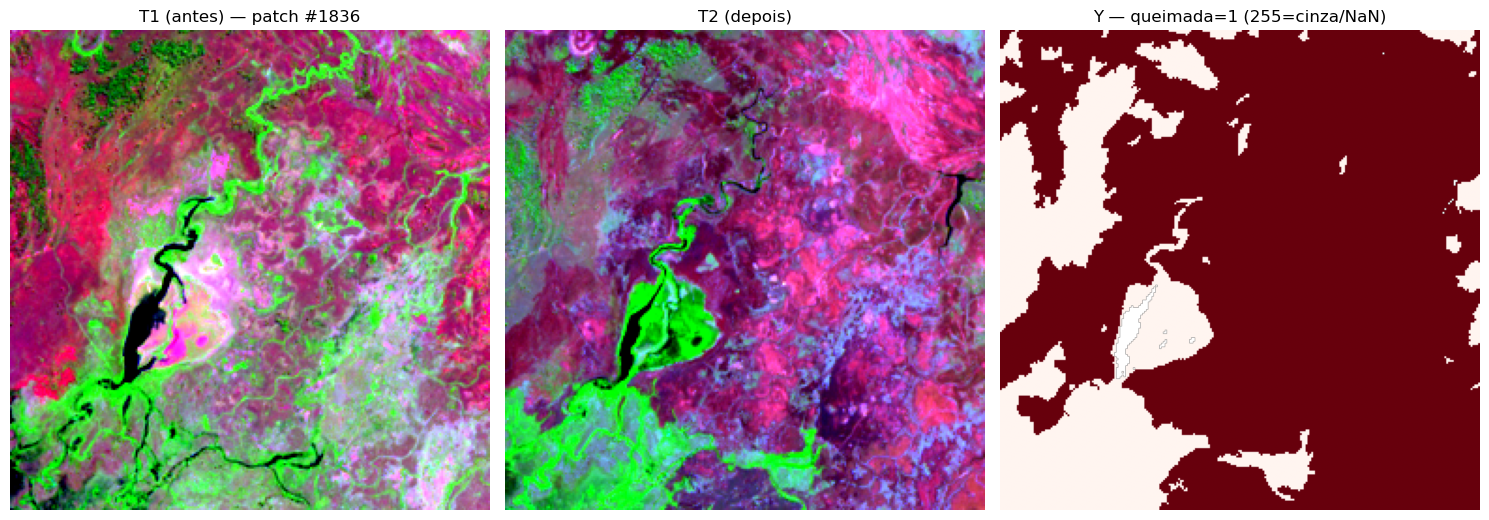

patch #1836: 49,674 pixels de queimada (75.8% do patch)


In [5]:
def falsecor(p4):
    """(4,H,W) [B04,B8A,B11,B12] -> RGB SWIR2/NIR/Red com stretch 3-97%."""
    def st(x):
        x = x.astype("float32"); v = x[x > 0]
        if v.size == 0: return np.zeros_like(x)
        lo, hi = np.percentile(v, 3), np.percentile(v, 97)
        return np.clip((x-lo)/(hi-lo+1e-9), 0, 1)
    return np.dstack([st(p4[3]), st(p4[1]), st(p4[0])])   # R=SWIR2, G=NIR, B=Red

# patch com mais pixels de queimada (entre os primeiros 2000, p/ ser rápido)
queim = (np.asarray(Ytr[:2000]) == 1).sum(axis=(1,2))
i = int(queim.argmax())
T2 = carregar("train_v123_256_T2")
y = np.asarray(Ytr[i]).astype("float32"); y[y == 255] = np.nan   # inválido fica transparente

fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
ax[0].imshow(falsecor(np.asarray(T1[i]))); ax[0].set_title(f"T1 (antes) — patch #{i}")
ax[1].imshow(falsecor(np.asarray(T2[i]))); ax[1].set_title("T2 (depois)")
ax[2].imshow(y, cmap="Reds", vmin=0, vmax=1); ax[2].set_title("Y — queimada=1 (255=cinza/NaN)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print(f"patch #{i}: {int(queim[i]):,} pixels de queimada ({100*queim[i]/(256*256):.1f}% do patch)")

# <span style="color:#cf4c39">🗂️ 6. Os metadados: G, POS, SPLIT (e por que importam)</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

Além das imagens e do rótulo, o Dataset A traz três matrizes de **metadados por patch** (comprimento N):

- **`G`** — o **tile** MGRS de origem do patch (ex.: `"21KWB"` codificado). É o **grupo** para `GroupKFold`: patches do mesmo tile **nunca** caem ao mesmo tempo em treino e validação → evita **vazamento espacial** (o modelo não "decora" uma região).
- **`POS`** — `[par, linha, coluna]`: de qual **par de datas** (1, 2 ou 3 — o "v123") e de qual posição na grade do tile o patch foi recortado.
- **`SPLIT`** — `0 = treino`, `1 = validação` (partição estratificada 70/30 usada no estudo).

</div>

In [6]:
G     = carregar("train_v123_256_G",     mmap=False)
POS   = carregar("train_v123_256_POS",   mmap=False)
SPLIT = carregar("train_v123_256_SPLIT", mmap=False)

print("tiles distintos (grupos GroupKFold):", len(set(G.tolist())))
print("exemplos de tile:", sorted(set(G.tolist()))[:6], "...")
print("POS[0] = [par, linha, coluna] =", POS[0].tolist())
v, n = np.unique(SPLIT, return_counts=True)
print("SPLIT:", {int(k): int(x) for k, x in zip(v, n)}, " (0=treino, 1=validação)")

tiles distintos (grupos GroupKFold): 67
exemplos de tile: ['0_1', '0_2', '0_3', '0_5', '0_6', '10_1'] ...
POS[0] = [par, linha, coluna] = ['1', 0, 5632]
SPLIT: {0: 9437, 1: 3567}  (0=treino, 1=validação)


# <span style="color:#cf4c39">🧩 7. Carregando em seu próprio código</span>
<hr style="border:1px solid #e69627;">

<div style="text-align: justify; margin-right: 2.5%;">

O mínimo para começar a treinar: empilhe T1 e T2 no eixo dos canais (fica `(N,8,256,256)`) e use `Y` como alvo, ignorando os pixels `255`.

</div>

In [7]:
# exemplo: montar a entrada de um modelo "concat" (8 canais = 4 bandas x 2 datas)
i = 0
x = np.concatenate([np.asarray(T1[i]), np.asarray(T2[i])], axis=0)   # (8,256,256)
y = np.asarray(Ytr[i])                                               # (256,256) em {0,1,255}
valido = (y != 255)
print("entrada x:", x.shape, "| alvo y:", y.shape, "| pixels válidos:", int(valido.sum()))
print("reflectância: lembre de dividir por 10000 antes de alimentar o modelo.")

entrada x: (8, 256, 256) | alvo y: (256, 256) | pixels válidos: 42884
reflectância: lembre de dividir por 10000 antes de alimentar o modelo.


---
Continue no **`02_modelos_deep_learning`** para ver as arquiteturas que consomem estes patches.